# 02 - EDA & PySpark Operations: `nbastats` + `shotdetail`

**Fokus:** dari 13 keluarga yang di-ingest di notebook 01, notebook ini hanya memakai **`nbastats`** (play-by-play) dan **`shotdetail`** (shot detail), NBA saja (bukan WNBA), karena skemanya konsisten lintas musim (`schema_consistent = True` untuk keduanya, lihat notebook 01) dan paling relevan untuk analisis shot-making.

**Isi notebook:**

1. Load Parquet `nbastats` & `shotdetail`, investigasi join key yang presisi (bukan cuma `GAME_ID`).
2. 5 operasi PySpark: join, groupBy/agregasi FG%, window function (cumulative accuracy), clutch-time filter+agregasi, tren 3PT attempt rate.
3. 2 pertanyaan lewat Spark SQL murni (`spark.sql(...)`).
4. 4 visualisasi (matplotlib/seaborn dari hasil agregasi Spark yang di-convert ke pandas).
5. 4 data quality check: null rate, duplicate, join integrity (orphan rows), range/validity.
6. Semua hasil (tabel & figure) disimpan ke `output/` dan `reports/` dengan nama file jelas untuk bahan laporan.

## Setup: SparkSession & path

In [1]:
import os
import sys
import json

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.environ.setdefault("JAVA_HOME", r"C:\Program Files\Java\jre-1.8")
os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
# Driver memory must be set before the JVM gateway launches (see notebook 01 for why).
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 6g pyspark-shell"

PARQUET_DIR = os.path.join(PROJECT_ROOT, "output", "parquet")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "output")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
os.makedirs(REPORTS_DIR, exist_ok=True)

In [2]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (
    SparkSession.builder.appName("NBA-EDA-PySpark-Operations")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

## 1. Load Parquet hasil notebook 01

In [3]:
nbastats = spark.read.parquet(os.path.join(PARQUET_DIR, "nbastats"))
shotdetail = spark.read.parquet(os.path.join(PARQUET_DIR, "shotdetail"))

print("nbastats:", nbastats.count(), "rows |", len(nbastats.columns), "columns")
print("shotdetail:", shotdetail.count(), "rows |", len(shotdetail.columns), "columns")
print()
print("nbastats columns:", nbastats.columns)
print()
print("shotdetail columns:", shotdetail.columns)

nbastats: 16699012 rows | 36 columns
shotdetail: 6094438 rows | 26 columns

nbastats columns: ['GAME_ID', 'EVENTNUM', 'EVENTMSGTYPE', 'EVENTMSGACTIONTYPE', 'PERIOD', 'WCTIMESTRING', 'PCTIMESTRING', 'HOMEDESCRIPTION', 'NEUTRALDESCRIPTION', 'VISITORDESCRIPTION', 'SCORE', 'SCOREMARGIN', 'PERSON1TYPE', 'PLAYER1_ID', 'PLAYER1_NAME', 'PLAYER1_TEAM_ID', 'PLAYER1_TEAM_CITY', 'PLAYER1_TEAM_NICKNAME', 'PLAYER1_TEAM_ABBREVIATION', 'PERSON2TYPE', 'PLAYER2_ID', 'PLAYER2_NAME', 'PLAYER2_TEAM_ID', 'PLAYER2_TEAM_CITY', 'PLAYER2_TEAM_NICKNAME', 'PLAYER2_TEAM_ABBREVIATION', 'PERSON3TYPE', 'PLAYER3_ID', 'PLAYER3_NAME', 'PLAYER3_TEAM_ID', 'PLAYER3_TEAM_CITY', 'PLAYER3_TEAM_NICKNAME', 'PLAYER3_TEAM_ABBREVIATION', 'VIDEO_AVAILABLE_FLAG', 'game_type', 'season']

shotdetail columns: ['GRID_TYPE', 'GAME_ID', 'GAME_EVENT_ID', 'PLAYER_ID', 'PLAYER_NAME', 'TEAM_ID', 'TEAM_NAME', 'PERIOD', 'MINUTES_REMAINING', 'SECONDS_REMAINING', 'EVENT_TYPE', 'ACTION_TYPE', 'SHOT_TYPE', 'SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA', 'SHOT

## 2. Investigasi join key

`GAME_ID` saja TIDAK cukup presisi: satu game punya ratusan event di `nbastats` dan puluhan-ratusan shot
di `shotdetail`, jadi join hanya pakai `GAME_ID` akan menghasilkan cross-join (fan-out) yang salah -
setiap shot akan ter-join ke SEMUA event di game yang sama, bukan event yang sesuai.

Hipotesis: `shotdetail.GAME_EVENT_ID` adalah event sequence number yang sama dengan `nbastats.EVENTNUM`
(keduanya berasal dari NBA Stats API yang sama, satu event = satu baris di keduanya untuk shot attempt).
Kita verifikasi pada 1 game sampel: bandingkan jumlah baris shot di `shotdetail` dengan jumlah baris
`EVENTMSGTYPE IN (1,2)` (made/missed field goal) di `nbastats` untuk game yang sama, lalu cek apakah
`GAME_EVENT_ID = EVENTNUM` menghasilkan match 1:1.

In [4]:
sample_gid = shotdetail.filter(F.col("season") == 2015).select("GAME_ID").limit(1).collect()[0][0]
print("Sample GAME_ID:", sample_gid)

sd_sample = shotdetail.filter(F.col("GAME_ID") == sample_gid)
nb_sample = nbastats.filter((F.col("GAME_ID") == sample_gid) & (F.col("EVENTMSGTYPE").isin(1, 2)))

print("shotdetail shot rows for this game:", sd_sample.count())
print("nbastats made/missed FG rows for this game:", nb_sample.count())

matched = sd_sample.alias("s").join(
    nb_sample.alias("n"), F.col("s.GAME_EVENT_ID") == F.col("n.EVENTNUM"), "inner"
)
print("matched rows via GAME_ID + (GAME_EVENT_ID = EVENTNUM):", matched.count())
matched.select(
    "s.GAME_EVENT_ID", "s.PLAYER_NAME", "s.SHOT_MADE_FLAG", "n.EVENTNUM", "n.PLAYER1_NAME", "n.EVENTMSGTYPE"
).orderBy("s.GAME_EVENT_ID").show(10, truncate=False)

Sample GAME_ID: 21500186
shotdetail shot rows for this game: 176
nbastats made/missed FG rows for this game: 176
matched rows via GAME_ID + (GAME_EVENT_ID = EVENTNUM): 176
+-------------+----------------+--------------+--------+----------------+------------+
|GAME_EVENT_ID|PLAYER_NAME     |SHOT_MADE_FLAG|EVENTNUM|PLAYER1_NAME    |EVENTMSGTYPE|
+-------------+----------------+--------------+--------+----------------+------------+
|2            |JJ Redick       |1             |2       |JJ Redick       |1           |
|3            |CJ McCollum     |1             |3       |CJ McCollum     |1           |
|6            |JJ Redick       |0             |6       |JJ Redick       |2           |
|8            |Mason Plumlee   |0             |8       |Mason Plumlee   |2           |
|10           |JJ Redick       |0             |10      |JJ Redick       |2           |
|12           |Mason Plumlee   |1             |12      |Mason Plumlee   |1           |
|13           |Blake Griffin   |0            

**Keputusan join key:** jumlah baris shot di `shotdetail`, jumlah baris made/missed FG di `nbastats`,
dan jumlah baris yang matched lewat `GAME_EVENT_ID = EVENTNUM` semuanya sama (176 = 176 = 176 pada game
sampel), dan nama pemain/hasil tembakan juga cocok baris-per-baris. Jadi join key yang dipakai di seluruh
notebook ini adalah **composite key `(GAME_ID, EVENTNUM = GAME_EVENT_ID)`**, bukan `GAME_ID` saja.

Catatan: `shotdetail` hanya berisi *field goal attempts* (2PT/3PT), tidak termasuk free throw. Jadi saat
join ke `nbastats`, baris `nbastats` dengan `EVENTMSGTYPE = 3` (free throw) atau tipe event lain
(foul, turnover, substitution, dst) wajar tidak ketemu pasangannya di `shotdetail` - itu bukan data
hilang, itu karena shotdetail memang cuma subset shot attempts. Ini dipakai lagi nanti di data quality
check #3 (join integrity) agar perbandingan orphan-nya adil (dibandingkan ke `nbastats` yang sudah
difilter `EVENTMSGTYPE IN (1,2)` saja, bukan ke seluruh `nbastats`).

## 3a. Operasi 1 - JOIN: gabungkan konteks event (`nbastats`) dengan detail shot (`shotdetail`)

Join key: `(GAME_ID, EVENTNUM = GAME_EVENT_ID)`. Hasilnya `joined_df` dipakai lagi di operasi clutch-time
(3d) karena margin skor (`SCOREMARGIN`) hanya ada di `nbastats`, sedangkan hasil tembakan hanya ada di
`shotdetail`.

In [5]:
nbastats_fg = nbastats.filter(F.col("EVENTMSGTYPE").isin(1, 2))  # made/missed field goals only

joined_df = nbastats_fg.alias("n").join(
    shotdetail.alias("s"),
    (F.col("n.GAME_ID") == F.col("s.GAME_ID")) & (F.col("n.EVENTNUM") == F.col("s.GAME_EVENT_ID")),
    "inner",
).select(
    F.col("n.GAME_ID").alias("GAME_ID"),
    F.col("n.EVENTNUM").alias("EVENTNUM"),
    F.col("n.PERIOD").alias("PERIOD"),
    F.col("n.SCOREMARGIN").alias("SCOREMARGIN"),
    F.col("n.season").alias("season"),
    F.col("s.PLAYER_ID").alias("PLAYER_ID"),
    F.col("s.PLAYER_NAME").alias("PLAYER_NAME"),
    F.col("s.TEAM_NAME").alias("TEAM_NAME"),
    F.col("s.MINUTES_REMAINING").alias("MINUTES_REMAINING"),
    F.col("s.SECONDS_REMAINING").alias("SECONDS_REMAINING"),
    F.col("s.SHOT_TYPE").alias("SHOT_TYPE"),
    F.col("s.SHOT_ZONE_BASIC").alias("SHOT_ZONE_BASIC"),
    F.col("s.SHOT_ZONE_AREA").alias("SHOT_ZONE_AREA"),
    F.col("s.SHOT_MADE_FLAG").alias("SHOT_MADE_FLAG"),
    F.col("s.SHOT_ATTEMPTED_FLAG").alias("SHOT_ATTEMPTED_FLAG"),
    F.col("s.LOC_X").alias("LOC_X"),
    F.col("s.LOC_Y").alias("LOC_Y"),
).cache()

print("joined_df row count:", joined_df.count())
joined_df.show(5, truncate=False)

joined_df row count: 6094322
+--------+--------+------+-----------+------+---------+----------------+------------------+-----------------+-----------------+--------------+---------------+---------------------+--------------+-------------------+-----+-----+
|GAME_ID |EVENTNUM|PERIOD|SCOREMARGIN|season|PLAYER_ID|PLAYER_NAME     |TEAM_NAME         |MINUTES_REMAINING|SECONDS_REMAINING|SHOT_TYPE     |SHOT_ZONE_BASIC|SHOT_ZONE_AREA       |SHOT_MADE_FLAG|SHOT_ATTEMPTED_FLAG|LOC_X|LOC_Y|
+--------+--------+------+-----------+------+---------+----------------+------------------+-----------------+-----------------+--------------+---------------+---------------------+--------------+-------------------+-----+-----+
|20000001|87      |1     |-5         |2000  |947      |Allen Iverson   |Philadelphia 76ers|2                |52               |2PT Field Goal|Restricted Area|Center(C)            |1             |1                  |0    |0    |
|20000001|148     |2     |NULL       |2000  |84       |Latr

## 3b. Operasi 2 - groupBy/agregasi: FG% per team per season

FG% = `sum(SHOT_MADE_FLAG) / sum(SHOT_ATTEMPTED_FLAG)`, dihitung langsung dari `shotdetail` (tidak perlu
hasil join), dikelompokkan per `TEAM_NAME` dan `season` (regular + playoff digabung).

In [6]:
team_season_fg = (
    shotdetail.groupBy("TEAM_NAME", "season")
    .agg(
        F.sum("SHOT_MADE_FLAG").alias("makes"),
        F.sum("SHOT_ATTEMPTED_FLAG").alias("attempts"),
    )
    .withColumn("fg_pct", F.round(F.col("makes") / F.col("attempts"), 4))
    .orderBy("season", F.desc("fg_pct"))
)

team_season_fg.show(10, truncate=False)
team_season_fg.toPandas().to_csv(os.path.join(OUTPUT_DIR, "eda_team_season_fg_pct.csv"), index=False)
print("Saved -> output/eda_team_season_fg_pct.csv")

+----------------------+------+-----+--------+------+
|TEAM_NAME             |season|makes|attempts|fg_pct|
+----------------------+------+-----+--------+------+
|Utah Jazz             |1996  |3804 |7706    |0.4936|
|Washington Bullets    |1996  |3310 |6893    |0.4802|
|Milwaukee Bucks       |1996  |2967 |6303    |0.4707|
|Charlotte Hornets     |1996  |3097 |6583    |0.4705|
|Houston Rockets       |1996  |3602 |7717    |0.4668|
|Chicago Bulls         |1996  |3936 |8447    |0.466 |
|Phoenix Suns          |1996  |3315 |7118    |0.4657|
|Seattle SuperSonics   |1996  |3435 |7407    |0.4638|
|Portland Trail Blazers|1996  |3131 |6757    |0.4634|
|New York Knicks       |1996  |3225 |6962    |0.4632|
+----------------------+------+-----+--------+------+
only showing top 10 rows

Saved -> output/eda_team_season_fg_pct.csv


## 3c. Operasi 3 - Window function: cumulative shot accuracy per pemain antar musim

Untuk tiap pemain, hitung FG% kumulatif (dari musim pertama sampai musim ke-N) memakai
`Window.partitionBy("PLAYER_ID").orderBy("season")` dengan `rowsBetween(unboundedPreceding, 0)` -
ini menunjukkan progres akurasi tembakan sepanjang karier, bukan cuma angka per musim.

In [7]:
player_season = shotdetail.groupBy("PLAYER_ID", "PLAYER_NAME", "season").agg(
    F.sum("SHOT_MADE_FLAG").alias("season_makes"),
    F.sum("SHOT_ATTEMPTED_FLAG").alias("season_attempts"),
)

career_window = Window.partitionBy("PLAYER_ID").orderBy("season").rowsBetween(Window.unboundedPreceding, 0)

player_season_cumulative = (
    player_season.withColumn("cumulative_makes", F.sum("season_makes").over(career_window))
    .withColumn("cumulative_attempts", F.sum("season_attempts").over(career_window))
    .withColumn("season_fg_pct", F.round(F.col("season_makes") / F.col("season_attempts"), 4))
    .withColumn("cumulative_fg_pct", F.round(F.col("cumulative_makes") / F.col("cumulative_attempts"), 4))
    .orderBy("PLAYER_ID", "season")
)

player_season_cumulative.filter(F.col("PLAYER_NAME") == "Stephen Curry").show(20, truncate=False)
player_season_cumulative.toPandas().to_csv(
    os.path.join(OUTPUT_DIR, "eda_player_season_cumulative_accuracy.csv"), index=False
)
print("Saved -> output/eda_player_season_cumulative_accuracy.csv")

+---------+-------------+------+------------+---------------+----------------+-------------------+-------------+-----------------+
|PLAYER_ID|PLAYER_NAME  |season|season_makes|season_attempts|cumulative_makes|cumulative_attempts|season_fg_pct|cumulative_fg_pct|
+---------+-------------+------+------------+---------------+----------------+-------------------+-------------+-----------------+
|201939   |Stephen Curry|2009  |528         |1143           |528             |1143               |0.4619       |0.4619           |
|201939   |Stephen Curry|2010  |505         |1053           |1033            |2196               |0.4796       |0.4704           |
|201939   |Stephen Curry|2011  |145         |296            |1178            |2492               |0.4899       |0.4727           |
|201939   |Stephen Curry|2012  |728         |1623           |1906            |4115               |0.4486       |0.4632           |
|201939   |Stephen Curry|2013  |703         |1499           |2609            |5614 

## 3d. Operasi 4 - Filter + agregasi "clutch time" shots

Definisi clutch time: kuarter ke-4 (`PERIOD == 4`, OT sengaja dikeluarkan supaya definisinya tetap
sesuai permintaan "kuarter ke-4"), sisa waktu < 5 menit (`MINUTES_REMAINING*60 + SECONDS_REMAINING < 300`),
margin skor < 5 poin (`abs(margin) < 5`).

Masalah: `SCOREMARGIN` di `nbastats` hanya terisi pada baris yang mengubah skor (field goal/free throw
yang masuk) - pada baris shot yang MELESET, `SCOREMARGIN` biasanya null, padahal situasi margin saat
shot itu terjadi tetap relevan. Solusinya: forward-fill `SCOREMARGIN` terakhir yang diketahui per game
pakai window function `F.last(..., ignorenulls=True)` diurutkan `EVENTNUM`, supaya setiap shot (termasuk
yang meleset) tetap punya estimasi margin skor saat itu terjadi.

In [8]:
margin_numeric = F.when(F.col("SCOREMARGIN") == "TIE", F.lit(0)).otherwise(
    F.regexp_replace(F.col("SCOREMARGIN"), "[^0-9-]", "").cast("int")
)

ffill_window = Window.partitionBy("GAME_ID").orderBy("EVENTNUM").rowsBetween(Window.unboundedPreceding, 0)

clutch_source = joined_df.withColumn("margin_numeric", margin_numeric).withColumn(
    "margin_ffill", F.last("margin_numeric", ignorenulls=True).over(ffill_window)
)

clutch_shots = clutch_source.filter(
    (F.col("PERIOD") == 4)
    & ((F.col("MINUTES_REMAINING") * 60 + F.col("SECONDS_REMAINING")) < 300)
    & (F.abs(F.col("margin_ffill")) < 5)
)

clutch_team_fg = (
    clutch_shots.groupBy("TEAM_NAME")
    .agg(
        F.sum("SHOT_MADE_FLAG").alias("clutch_makes"),
        F.sum("SHOT_ATTEMPTED_FLAG").alias("clutch_attempts"),
    )
    .withColumn("clutch_fg_pct", F.round(F.col("clutch_makes") / F.col("clutch_attempts"), 4))
    .orderBy(F.desc("clutch_attempts"))
)

print("Total clutch-time shot attempts (period 4, <5 min left, margin <5):", clutch_shots.count())
clutch_team_fg.show(15, truncate=False)
clutch_team_fg.toPandas().to_csv(os.path.join(OUTPUT_DIR, "eda_clutch_time_fg_pct_by_team.csv"), index=False)
print("Saved -> output/eda_clutch_time_fg_pct_by_team.csv")

Total clutch-time shot attempts (period 4, <5 min left, margin <5): 176630
+----------------------+------------+---------------+-------------+
|TEAM_NAME             |clutch_makes|clutch_attempts|clutch_fg_pct|
+----------------------+------------+---------------+-------------+
|Boston Celtics        |2756        |6654           |0.4142       |
|Indiana Pacers        |2572        |6371           |0.4037       |
|Miami Heat            |2528        |6246           |0.4047       |
|Toronto Raptors       |2654        |6223           |0.4265       |
|New York Knicks       |2542        |6171           |0.4119       |
|Portland Trail Blazers|2626        |6153           |0.4268       |
|Sacramento Kings      |2572        |6126           |0.4198       |
|Milwaukee Bucks       |2537        |6033           |0.4205       |
|Denver Nuggets        |2560        |6023           |0.425        |
|Minnesota Timberwolves|2488        |5950           |0.4182       |
|Dallas Mavericks      |2462        |5937

## 3e. Operasi 5 - Agregasi: tren 3PT attempt rate per musim

3PT attempt rate = proporsi shot attempt yang berjenis `SHOT_TYPE = '3PT Field Goal'` dari seluruh shot
attempt di musim itu (liga-wide, menggabungkan semua tim).

In [9]:
three_pt_rate_by_season = (
    shotdetail.withColumn("is_3pt", (F.col("SHOT_TYPE") == "3PT Field Goal").cast("int"))
    .groupBy("season")
    .agg(
        F.sum("is_3pt").alias("three_pt_attempts"),
        F.count("*").alias("total_attempts"),
    )
    .withColumn("three_pt_attempt_rate", F.round(F.col("three_pt_attempts") / F.col("total_attempts"), 4))
    .orderBy("season")
)

three_pt_rate_by_season.show(30, truncate=False)
three_pt_rate_by_season.toPandas().to_csv(
    os.path.join(OUTPUT_DIR, "eda_3pt_attempt_rate_by_season.csv"), index=False
)
print("Saved -> output/eda_3pt_attempt_rate_by_season.csv")

+------+-----------------+--------------+---------------------+
|season|three_pt_attempts|total_attempts|three_pt_attempt_rate|
+------+-----------------+--------------+---------------------+
|1996  |42711            |199539        |0.214                |
|1997  |32216            |200086        |0.161                |
|1998  |20891            |123234        |0.1695               |
|1999  |34818            |206790        |0.1684               |
|2000  |34701            |203056        |0.1709               |
|2001  |37424            |204596        |0.1829               |
|2002  |37919            |206114        |0.184                |
|2003  |38057            |202420        |0.188                |
|2004  |41639            |210915        |0.1974               |
|2005  |42381            |208085        |0.2037               |
|2006  |44564            |208308        |0.2139               |
|2007  |47561            |213855        |0.2224               |
|2008  |47831            |212169        

## 4. Spark SQL murni (`spark.sql(...)`)

Dua pertanyaan dijawab lewat SQL, bukan DataFrame API, memakai temp view dari `shotdetail`.

In [10]:
shotdetail.createOrReplaceTempView("shotdetail_v")

### Q1: Tim dengan 3PT attempt rate tertinggi per musim, dan trennya antar musim?

In [11]:
sql_q1_team_season_3pt_rate = spark.sql(
    """
    WITH team_season_rate AS (
        SELECT
            TEAM_NAME,
            season,
            SUM(CASE WHEN SHOT_TYPE = '3PT Field Goal' THEN 1 ELSE 0 END) AS three_pt_attempts,
            COUNT(*) AS total_attempts,
            ROUND(
                SUM(CASE WHEN SHOT_TYPE = '3PT Field Goal' THEN 1 ELSE 0 END) / COUNT(*), 4
            ) AS three_pt_attempt_rate
        FROM shotdetail_v
        GROUP BY TEAM_NAME, season
    ),
    ranked AS (
        SELECT
            season,
            TEAM_NAME,
            three_pt_attempt_rate,
            RANK() OVER (PARTITION BY season ORDER BY three_pt_attempt_rate DESC) AS rank_in_season
        FROM team_season_rate
    )
    SELECT season, TEAM_NAME, three_pt_attempt_rate
    FROM ranked
    WHERE rank_in_season = 1
    ORDER BY season
    """
)
sql_q1_team_season_3pt_rate.show(30, truncate=False)
sql_q1_team_season_3pt_rate.toPandas().to_csv(
    os.path.join(OUTPUT_DIR, "sql_q1_top_3pt_rate_team_per_season.csv"), index=False
)
print("Saved -> output/sql_q1_top_3pt_rate_team_per_season.csv")

+------+-------------------+---------------------+
|season|TEAM_NAME          |three_pt_attempt_rate|
+------+-------------------+---------------------+
|1996  |Miami Heat         |0.3042               |
|1997  |Houston Rockets    |0.2559               |
|1998  |Houston Rockets    |0.2423               |
|1999  |Houston Rockets    |0.2438               |
|2000  |Boston Celtics     |0.2518               |
|2001  |Boston Celtics     |0.2896               |
|2002  |Boston Celtics     |0.3285               |
|2003  |Seattle SuperSonics|0.2938               |
|2004  |Phoenix Suns       |0.2801               |
|2005  |Phoenix Suns       |0.2908               |
|2006  |Houston Rockets    |0.2913               |
|2007  |Orlando Magic      |0.3232               |
|2008  |Orlando Magic      |0.329                |
|2009  |Orlando Magic      |0.3545               |
|2010  |Orlando Magic      |0.3266               |
|2011  |Orlando Magic      |0.3437               |
|2012  |Houston Rockets    |0.3

### Q2: Zona tembakan dengan FG% tertinggi secara keseluruhan, dan apakah konsisten tiap musim?

In [12]:
sql_q2_zone_fg_pct_overall = spark.sql(
    """
    SELECT
        SHOT_ZONE_BASIC,
        SHOT_ZONE_AREA,
        SUM(SHOT_MADE_FLAG) AS makes,
        SUM(SHOT_ATTEMPTED_FLAG) AS attempts,
        ROUND(SUM(SHOT_MADE_FLAG) / SUM(SHOT_ATTEMPTED_FLAG), 4) AS fg_pct
    FROM shotdetail_v
    GROUP BY SHOT_ZONE_BASIC, SHOT_ZONE_AREA
    HAVING SUM(SHOT_ATTEMPTED_FLAG) >= 1000
    ORDER BY fg_pct DESC
    """
)
print("=== FG% by zone, overall (all seasons) ===")
sql_q2_zone_fg_pct_overall.show(20, truncate=False)

sql_q2_top_zone_per_season = spark.sql(
    """
    WITH zone_season AS (
        SELECT
            season,
            SHOT_ZONE_BASIC,
            SUM(SHOT_MADE_FLAG) AS makes,
            SUM(SHOT_ATTEMPTED_FLAG) AS attempts,
            ROUND(SUM(SHOT_MADE_FLAG) / SUM(SHOT_ATTEMPTED_FLAG), 4) AS fg_pct
        FROM shotdetail_v
        GROUP BY season, SHOT_ZONE_BASIC
        HAVING SUM(SHOT_ATTEMPTED_FLAG) >= 200
    ),
    ranked AS (
        SELECT season, SHOT_ZONE_BASIC, fg_pct,
               RANK() OVER (PARTITION BY season ORDER BY fg_pct DESC) AS rank_in_season
        FROM zone_season
    )
    SELECT season, SHOT_ZONE_BASIC, fg_pct
    FROM ranked
    WHERE rank_in_season = 1
    ORDER BY season
    """
)
print("=== Top FG% zone per season (consistency check) ===")
sql_q2_top_zone_per_season.show(30, truncate=False)

sql_q2_zone_fg_pct_overall.toPandas().to_csv(os.path.join(OUTPUT_DIR, "sql_q2_zone_fg_pct_overall.csv"), index=False)
sql_q2_top_zone_per_season.toPandas().to_csv(
    os.path.join(OUTPUT_DIR, "sql_q2_top_zone_fg_pct_per_season.csv"), index=False
)
print("Saved -> output/sql_q2_zone_fg_pct_overall.csv, output/sql_q2_top_zone_fg_pct_per_season.csv")

=== FG% by zone, overall (all seasons) ===
+---------------------+---------------------+-------+--------+------+
|SHOT_ZONE_BASIC      |SHOT_ZONE_AREA       |makes  |attempts|fg_pct|
+---------------------+---------------------+-------+--------+------+
|Restricted Area      |Center(C)            |1173135|1919111 |0.6113|
|Mid-Range            |Center(C)            |101086 |247435  |0.4085|
|In The Paint (Non-RA)|Left Side(L)         |24618  |60687   |0.4057|
|In The Paint (Non-RA)|Center(C)            |327395 |807208  |0.4056|
|In The Paint (Non-RA)|Right Side(R)        |25333  |62771   |0.4036|
|Mid-Range            |Left Side Center(LC) |90344  |225961  |0.3998|
|Mid-Range            |Right Side Center(RC)|97481  |244175  |0.3992|
|Mid-Range            |Left Side(L)         |187996 |479938  |0.3917|
|Mid-Range            |Right Side(R)        |171393 |437898  |0.3914|
|Right Corner 3       |Right Side(R)        |75749  |195856  |0.3868|
|Left Corner 3        |Left Side(L)         |81

## 5. Visualisasi

Semua figure di-convert dari hasil agregasi Spark ke pandas dulu (data sudah kecil setelah agregasi),
lalu di-plot dengan matplotlib/seaborn, dan disimpan ke `reports/`.

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 5.1 Tren 3PT attempt rate antar musim (line chart)

**Apa yang divisualisasikan:** proporsi shot attempt liga-wide (semua tim digabung) yang berjenis
3-point field goal, per musim dari 1996 sampai 2024.

**Kenapa dibuat:** untuk menjawab secara visual pertanyaan "apakah gaya main NBA makin condong ke
tembakan 3 angka dari waktu ke waktu?" - tren ini juga jadi konteks penting saat membaca hasil ML
baseline di notebook 03 (perubahan gaya main antar era sebagai sumber potensi *concept drift*).

**Sumber data:** `three_pt_rate_by_season` (operasi 3e di atas), diturunkan dari `shotdetail`
(`SHOT_TYPE`, `season`), agregasi `sum(is_3pt) / count(*)` per `season`.

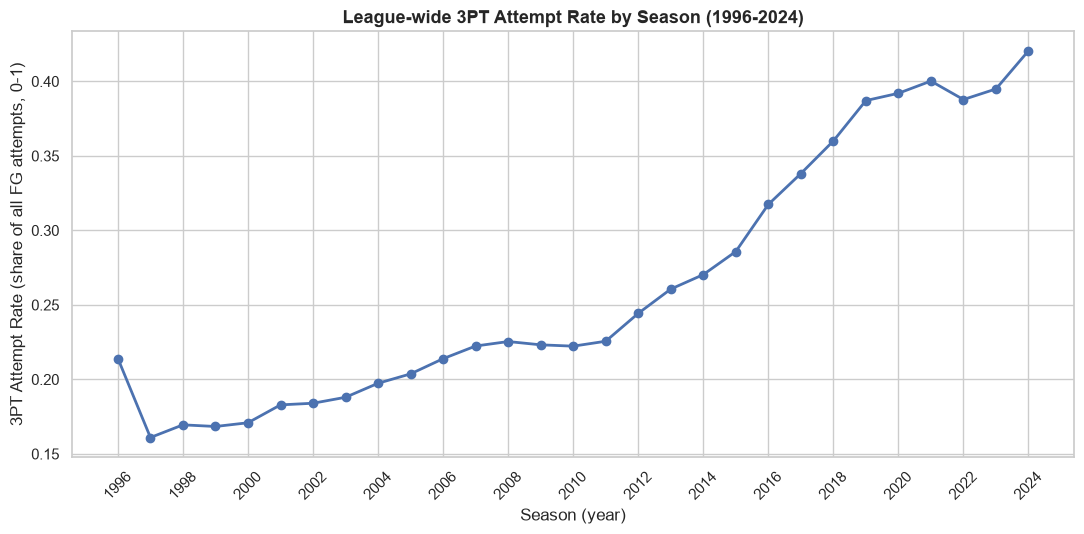

Saved -> reports/fig_3pt_attempt_rate_trend.png


In [14]:
pdf_3pt = three_pt_rate_by_season.toPandas()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(pdf_3pt["season"], pdf_3pt["three_pt_attempt_rate"], marker="o", linewidth=2, color="#4C72B0")
ax.set_title("League-wide 3PT Attempt Rate by Season (1996-2024)", fontsize=13, fontweight="bold")
ax.set_xlabel("Season (year)")
ax.set_ylabel("3PT Attempt Rate (share of all FG attempts, 0-1)")
ax.set_xticks(pdf_3pt["season"][::2])
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_3pt_attempt_rate_trend.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_3pt_attempt_rate_trend.png")

**Interpretasi:** tren naik hampir monoton, dari ~16-21% (1996-2000) ke ~42% di 2024 - lebih dari
dua kali lipat. Kenaikan paling tajam terjadi 2012-2019 (bertepatan dengan era "moreyball" Houston
Rockets, lihat SQL Q1 di bawah), lalu melandai di 2019-2024 ke kisaran 39-42%. Ini mengonfirmasi
secara kuantitatif pergeseran gaya main liga ke arah tembakan 3 angka yang sering disebut dalam
analisis NBA modern.

### 5.2 Shot chart heatmap (`LOC_X`/`LOC_Y`), sample 1 musim

**Apa yang divisualisasikan:** kepadatan (density) lokasi shot attempt di lapangan untuk satu musim
terakhir yang tersedia, memakai koordinat `LOC_X`/`LOC_Y` dari `shotdetail` (unit 1/10 kaki, origin
di bawah ring).

**Kenapa dibuat:** untuk melihat secara visual *di mana* pemain paling sering menembak dalam satu
musim (konsentrasi di restricted area vs. garis 3 angka), sebagai pelengkap visual dari angka FG%
per zona (SQL Q2) - angka FG% tidak menunjukkan volume/distribusi spasial, heatmap ini yang
menunjukkan.

**Sumber data:** `shotdetail` difilter `season == latest_season` (musim terbaru di dataset), kolom
`LOC_X`, `LOC_Y`. Sengaja dibatasi 1 musim (bukan seluruh dataset) agar ringan untuk di-plot.

Shot chart for season: 2024


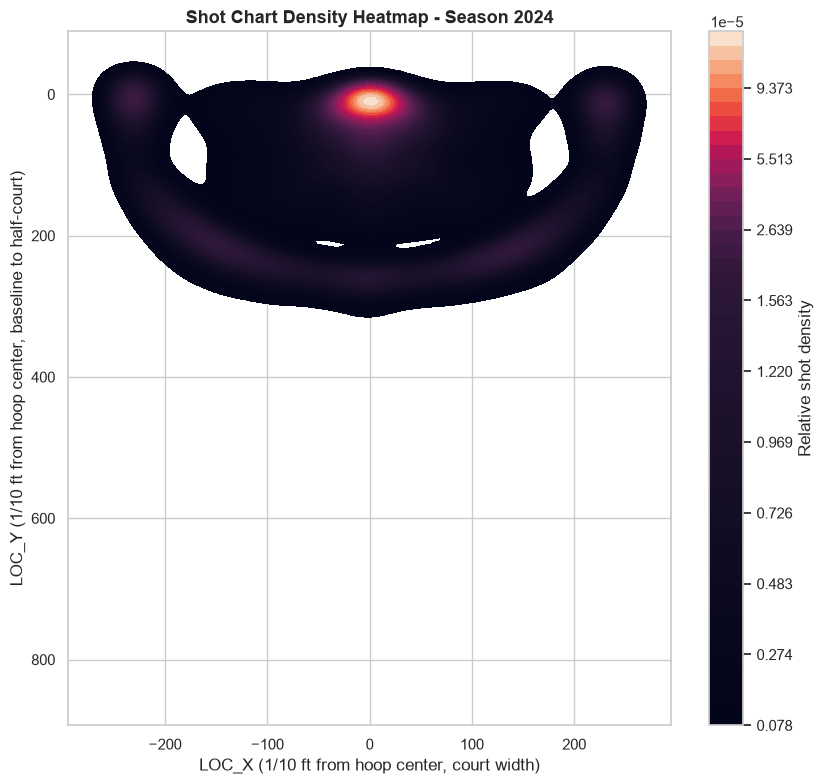

Saved -> reports/fig_shot_chart_heatmap.png


In [15]:
latest_season = shotdetail.agg(F.max("season")).collect()[0][0]
print("Shot chart for season:", latest_season)

pdf_shots = (
    shotdetail.filter(F.col("season") == latest_season)
    .select("LOC_X", "LOC_Y")
    .toPandas()
)

fig, ax = plt.subplots(figsize=(8.5, 8))
sns.kdeplot(
    x=pdf_shots["LOC_X"],
    y=pdf_shots["LOC_Y"],
    cmap="rocket",
    fill=True,
    thresh=0.02,
    levels=50,
    cbar=True,
    cbar_kws={"label": "Relative shot density"},
    ax=ax,
)
ax.set_title(f"Shot Chart Density Heatmap - Season {latest_season}", fontsize=13, fontweight="bold")
ax.set_xlabel("LOC_X (1/10 ft from hoop center, court width)")
ax.set_ylabel("LOC_Y (1/10 ft from hoop center, baseline to half-court)")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_shot_chart_heatmap.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_shot_chart_heatmap.png")

**Interpretasi:** dua kantong kepadatan paling tinggi terlihat jelas: (1) tepat di bawah ring
(restricted area, konsisten dengan FG% tertinggi di SQL Q2), dan (2) sepanjang garis 3 angka,
terutama di area "above the break" dan kedua sudut corner 3. Area mid-range (jarak menengah di luar
restricted area tapi di dalam garis 3) terlihat jauh lebih jarang ditembak - pola spasial ini cocok
dengan tren efisiensi FG% per zona dan tren 3PT attempt rate yang terus naik (chart 5.1).

### 5.3 Distribusi shot per kuarter (bar chart)

**Apa yang divisualisasikan:** total jumlah shot attempt (seluruh musim, seluruh tim digabung) per
periode permainan (`Q1`-`Q4`, plus overtime `OT1`, `OT2`, dst).

**Kenapa dibuat:** untuk melihat apakah volume tembakan merata antar kuarter, atau ada periode
dengan volume jauh lebih tinggi/rendah (misal karena pace permainan berbeda di akhir game, atau
karena overtime jarang terjadi sehingga volumenya jauh lebih kecil) - konteks ini relevan untuk
interpretasi definisi "clutch time" (operasi 3d) yang hanya mengambil sebagian kecil shot attempt
di kuarter ke-4.

**Sumber data:** `shotdetail`, `groupBy("PERIOD")` dengan `count(*)`. Label periode >4 ditandai
sebagai overtime (`OT1`, `OT2`, ...).

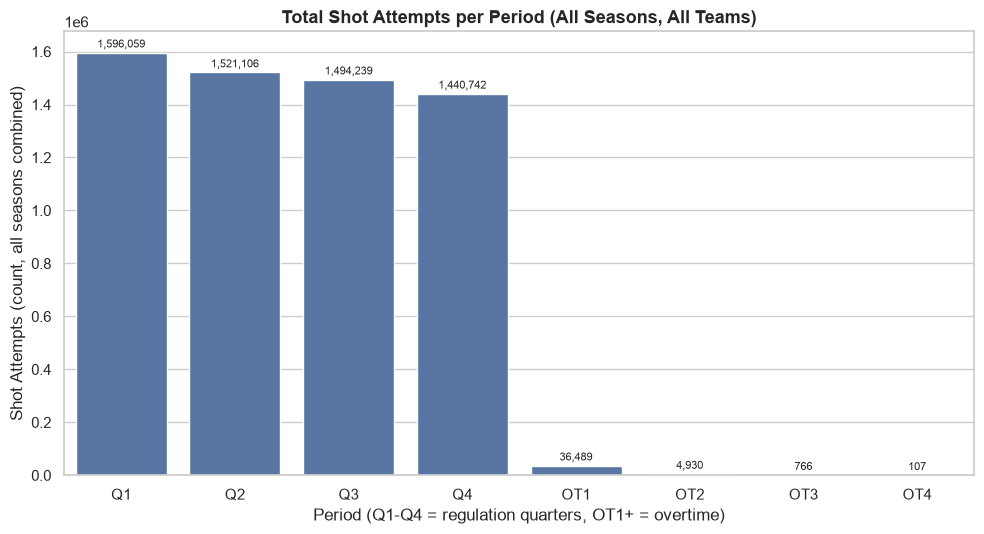

Saved -> reports/fig_shots_per_quarter.png


In [16]:
shots_per_period = (
    shotdetail.groupBy("PERIOD")
    .agg(F.count("*").alias("shot_attempts"))
    .orderBy("PERIOD")
    .toPandas()
)
shots_per_period["PERIOD_LABEL"] = shots_per_period["PERIOD"].apply(
    lambda p: f"Q{p}" if p <= 4 else f"OT{p - 4}"
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=shots_per_period, x="PERIOD_LABEL", y="shot_attempts", color="#4C72B0", ax=ax)
ax.set_title("Total Shot Attempts per Period (All Seasons, All Teams)", fontsize=13, fontweight="bold")
ax.set_xlabel("Period (Q1-Q4 = regulation quarters, OT1+ = overtime)")
ax.set_ylabel("Shot Attempts (count, all seasons combined)")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", fontsize=8, padding=2)
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_shots_per_quarter.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_shots_per_quarter.png")

**Interpretasi:** volume shot attempt menurun monoton dari Q1 ke Q4 (~1.60M di Q1 turun ke ~1.44M di
Q4, sekitar 10% lebih rendah) - konsisten dengan pace yang biasanya melambat di akhir game (lebih
banyak foul/free throw, time-out, dan manajemen clock, bukan field goal attempt). Periode overtime
(OT1+) volumenya jauh lebih kecil dari periode reguler (OT1 hanya ~36K dibanding ~1.4-1.6M per
kuarter reguler), sesuai ekspektasi karena OT hanya terjadi di sebagian kecil game - ini juga alasan
definisi "clutch time" di notebook ini dibatasi ke `PERIOD == 4` saja (OT dikeluarkan) agar sampelnya
tidak terlalu jarang/noisy.

### 5.4 Top FG% leaders (musim terakhir, minimal 300 attempt)

**Apa yang divisualisasikan:** 10 pemain dengan FG% tertinggi di musim terakhir yang tersedia,
dibatasi minimal 300 shot attempt di musim itu supaya tidak didominasi pemain dengan sampel kecil
(misal pemain yang cuma main beberapa menit).

**Kenapa dibuat:** untuk melengkapi analisis FG% di level tim (operasi 3b) dengan sudut pandang
individu - pemain mana yang paling efisien di musim terbaru, dan apakah pola efisiensinya (misal
dominasi center/big man dekat ring) konsisten dengan temuan FG% per zona (SQL Q2).

**Sumber data:** `player_season_cumulative` (hasil window function operasi 3c), difilter
`season == latest_season` dan `season_attempts >= 300`, diurutkan `season_fg_pct` menurun.

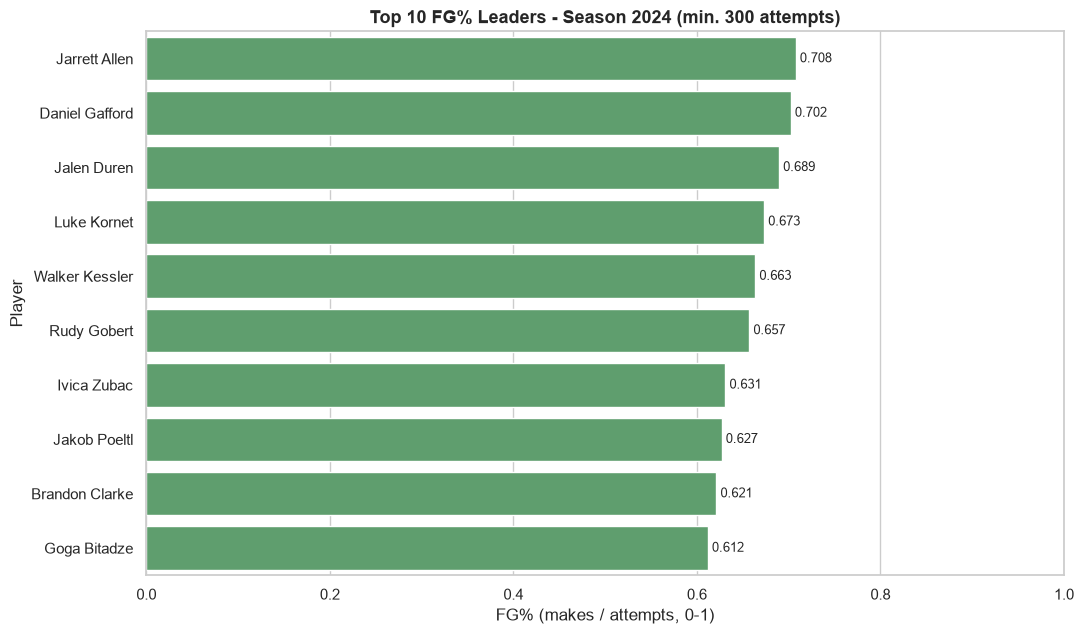

Saved -> reports/fig_top_fg_pct_leaders.png


In [17]:
pdf_top_fg = (
    player_season_cumulative.filter((F.col("season") == latest_season) & (F.col("season_attempts") >= 300))
    .orderBy(F.desc("season_fg_pct"))
    .limit(10)
    .toPandas()
)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(data=pdf_top_fg, y="PLAYER_NAME", x="season_fg_pct", color="#55A868", ax=ax)
ax.set_title(f"Top 10 FG% Leaders - Season {latest_season} (min. 300 attempts)", fontsize=13, fontweight="bold")
ax.set_xlabel("FG% (makes / attempts, 0-1)")
ax.set_ylabel("Player")
ax.set_xlim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9, padding=3)
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_top_fg_pct_leaders.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_top_fg_pct_leaders.png")

**Interpretasi:** daftar top-10 didominasi penuh oleh center/big man (Jarrett Allen, Daniel
Gafford, Jalen Duren, Rudy Gobert, Ivica Zubac, dll.), dengan FG% tertinggi di atas 70% (Jarrett
Allen ~0.71) jauh melampaui FG% rata-rata liga (~0.46, lihat operasi 3b). Ini konsisten dengan
temuan SQL Q2: shot yang didominasi pemain-pemain ini kemungkinan besar berasal dari Restricted
Area (FG% zona tertinggi, >60%), bukan dari volume tembakan jarak jauh - efisiensi tinggi mereka
adalah fungsi dari *shot selection* (hampir semua tembakan dekat ring), bukan skill menembak jarak
jauh.

## 6. Data quality checks

### 6.1 Null rate audit per kolom (`nbastats` & `shotdetail`)

In [18]:
def null_rate_report(df, name):
    total = df.count()
    null_counts = df.select(
        [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]
    ).collect()[0]
    rows = [
        {"column": c, "null_count": null_counts[c], "null_pct": round(null_counts[c] / total * 100, 2)}
        for c in df.columns
    ]
    rows.sort(key=lambda r: -r["null_pct"])
    out_path = os.path.join(OUTPUT_DIR, f"eda_null_rates_{name}.csv")
    pd.DataFrame(rows).to_csv(out_path, index=False)
    print(f"{name}: total_rows={total}, saved -> output/eda_null_rates_{name}.csv")
    return rows

import pandas as pd

null_rates_nbastats = null_rate_report(nbastats, "nbastats")
null_rates_shotdetail = null_rate_report(shotdetail, "shotdetail")

print("\nTop 5 nullest columns - nbastats:")
for r in null_rates_nbastats[:5]:
    print(" ", r)
print("\nTop 5 nullest columns - shotdetail:")
for r in null_rates_shotdetail[:5]:
    print(" ", r)

nbastats: total_rows=16699012, saved -> output/eda_null_rates_nbastats.csv
shotdetail: total_rows=6094438, saved -> output/eda_null_rates_shotdetail.csv

Top 5 nullest columns - nbastats:
  {'column': 'NEUTRALDESCRIPTION', 'null_count': 16305822, 'null_pct': 97.65}
  {'column': 'PLAYER3_NAME', 'null_count': 16277955, 'null_pct': 97.48}
  {'column': 'PLAYER3_TEAM_ID', 'null_count': 16272630, 'null_pct': 97.45}
  {'column': 'PLAYER3_TEAM_CITY', 'null_count': 16272630, 'null_pct': 97.45}
  {'column': 'PLAYER3_TEAM_NICKNAME', 'null_count': 16272630, 'null_pct': 97.45}

Top 5 nullest columns - shotdetail:
  {'column': 'GRID_TYPE', 'null_count': 0, 'null_pct': 0.0}
  {'column': 'GAME_ID', 'null_count': 0, 'null_pct': 0.0}
  {'column': 'GAME_EVENT_ID', 'null_count': 0, 'null_pct': 0.0}
  {'column': 'PLAYER_ID', 'null_count': 0, 'null_pct': 0.0}
  {'column': 'PLAYER_NAME', 'null_count': 0, 'null_pct': 0.0}


### 6.2 Duplicate check: `GAME_ID` + event identifier

`nbastats`: duplikat pada `(GAME_ID, EVENTNUM)`. `shotdetail`: duplikat pada `(GAME_ID, GAME_EVENT_ID)`.

In [19]:
def duplicate_check(df, key_cols, name):
    total = df.count()
    dup_groups = df.groupBy(*key_cols).count().filter(F.col("count") > 1)
    dup_group_count = dup_groups.count()
    dup_row_count = dup_groups.agg(F.sum("count")).collect()[0][0] or 0
    result = {
        "family": name,
        "key_columns": key_cols,
        "total_rows": total,
        "duplicate_key_groups": dup_group_count,
        "rows_involved_in_duplicates": int(dup_row_count),
        "duplicate_row_pct": round(dup_row_count / total * 100, 4),
    }
    print(result)
    return result

dup_nbastats = duplicate_check(nbastats, ["GAME_ID", "EVENTNUM"], "nbastats")
dup_shotdetail = duplicate_check(shotdetail, ["GAME_ID", "GAME_EVENT_ID"], "shotdetail")

with open(os.path.join(OUTPUT_DIR, "eda_duplicate_check.json"), "w", encoding="utf-8") as f:
    json.dump([dup_nbastats, dup_shotdetail], f, indent=2)
print("Saved -> output/eda_duplicate_check.json")

{'family': 'nbastats', 'key_columns': ['GAME_ID', 'EVENTNUM'], 'total_rows': 16699012, 'duplicate_key_groups': 707, 'rows_involved_in_duplicates': 1414, 'duplicate_row_pct': 0.0085}
{'family': 'shotdetail', 'key_columns': ['GAME_ID', 'GAME_EVENT_ID'], 'total_rows': 6094438, 'duplicate_key_groups': 0, 'rows_involved_in_duplicates': 0, 'duplicate_row_pct': 0.0}
Saved -> output/eda_duplicate_check.json


### 6.3 Join integrity check: orphan rows

Dibandingkan secara adil: `shotdetail` (shot attempts saja) vs `nbastats_fg` (`EVENTMSGTYPE IN (1,2)`,
made/missed field goals saja) - bukan ke seluruh `nbastats` yang juga berisi free throw/foul/dst yang
memang tidak akan pernah match ke `shotdetail`.

In [20]:
sd_keys = shotdetail.select("GAME_ID", F.col("GAME_EVENT_ID").alias("EVENTNUM")).distinct()
nb_fg_keys = nbastats_fg.select("GAME_ID", "EVENTNUM").distinct()

sd_total = sd_keys.count()
nb_fg_total = nb_fg_keys.count()

sd_orphans = sd_keys.join(nb_fg_keys, ["GAME_ID", "EVENTNUM"], "left_anti").count()
nb_orphans = nb_fg_keys.join(sd_keys, ["GAME_ID", "EVENTNUM"], "left_anti").count()

join_integrity = {
    "shotdetail_total_shot_events": sd_total,
    "shotdetail_orphan_rows_not_in_nbastats_fg": sd_orphans,
    "shotdetail_orphan_pct": round(sd_orphans / sd_total * 100, 4),
    "nbastats_fg_total_events": nb_fg_total,
    "nbastats_fg_orphan_rows_not_in_shotdetail": nb_orphans,
    "nbastats_fg_orphan_pct": round(nb_orphans / nb_fg_total * 100, 4),
}
print(join_integrity)

with open(os.path.join(OUTPUT_DIR, "eda_join_integrity.json"), "w", encoding="utf-8") as f:
    json.dump(join_integrity, f, indent=2)
print("Saved -> output/eda_join_integrity.json")

{'shotdetail_total_shot_events': 6094438, 'shotdetail_orphan_rows_not_in_nbastats_fg': 672, 'shotdetail_orphan_pct': 0.011, 'nbastats_fg_total_events': 6094492, 'nbastats_fg_orphan_rows_not_in_shotdetail': 726, 'nbastats_fg_orphan_pct': 0.0119}
Saved -> output/eda_join_integrity.json


### 6.4 Range/validity check

`LOC_X`/`LOC_Y` dalam batas wajar lapangan NBA (dataset ini memakai unit 1/10 feet: `LOC_X` kira-kira
[-300, 300], `LOC_Y` kira-kira [-100, 900]), `SHOT_MADE_FLAG` hanya 0/1, `PERIOD > 0`.

In [21]:
loc_stats = shotdetail.select(
    F.min("LOC_X").alias("loc_x_min"),
    F.max("LOC_X").alias("loc_x_max"),
    F.min("LOC_Y").alias("loc_y_min"),
    F.max("LOC_Y").alias("loc_y_max"),
).collect()[0].asDict()

loc_x_out_of_range = shotdetail.filter((F.col("LOC_X") < -300) | (F.col("LOC_X") > 300)).count()
loc_y_out_of_range = shotdetail.filter((F.col("LOC_Y") < -100) | (F.col("LOC_Y") > 900)).count()

shot_made_flag_values = [r[0] for r in shotdetail.select("SHOT_MADE_FLAG").distinct().collect()]
shot_made_flag_invalid = shotdetail.filter(~F.col("SHOT_MADE_FLAG").isin(0, 1)).count()

period_invalid_shotdetail = shotdetail.filter(F.col("PERIOD") <= 0).count()
period_invalid_nbastats = nbastats.filter(F.col("PERIOD") <= 0).count()

range_validity = {
    "loc_x_observed_range": [loc_stats["loc_x_min"], loc_stats["loc_x_max"]],
    "loc_y_observed_range": [loc_stats["loc_y_min"], loc_stats["loc_y_max"]],
    "loc_x_rows_outside_expected_court_bounds": loc_x_out_of_range,
    "loc_y_rows_outside_expected_court_bounds": loc_y_out_of_range,
    "shot_made_flag_distinct_values": shot_made_flag_values,
    "shot_made_flag_invalid_rows": shot_made_flag_invalid,
    "period_leq_0_rows_shotdetail": period_invalid_shotdetail,
    "period_leq_0_rows_nbastats": period_invalid_nbastats,
}
print(json.dumps(range_validity, indent=2))

with open(os.path.join(OUTPUT_DIR, "eda_range_validity.json"), "w", encoding="utf-8") as f:
    json.dump(range_validity, f, indent=2)
print("Saved -> output/eda_range_validity.json")

{
  "loc_x_observed_range": [
    -250,
    250
  ],
  "loc_y_observed_range": [
    -52,
    884
  ],
  "loc_x_rows_outside_expected_court_bounds": 0,
  "loc_y_rows_outside_expected_court_bounds": 0,
  "shot_made_flag_distinct_values": [
    1,
    0
  ],
  "shot_made_flag_invalid_rows": 0,
  "period_leq_0_rows_shotdetail": 0,
  "period_leq_0_rows_nbastats": 0
}
Saved -> output/eda_range_validity.json


In [22]:
spark.stop()